## Análisis de modelos

## KNN

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split,  GridSearchCV, ParameterGrid
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
import joblib
import mlflow

In [2]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


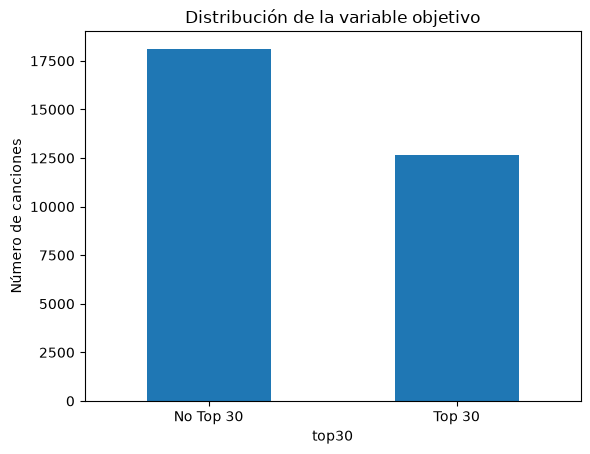

In [3]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Decimos a MLflow dónde guardar:

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")   
mlflow.set_experiment("experimento_musica")

<Experiment: artifact_location='file:c:/Users/Alicia.martinez/Desktop/Reto1_Alicia_XabierG_PIA-SAA-MIA/notebooks/mlruns/1', creation_time=1794509069348, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794509069348, lifecycle_stage='active', name='experimento_musica', tags={}, trace_location=None, workspace='default'>

## Separamos train y test:

In [5]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(18462, 13) (6154, 13) (6155, 13)
En train: 41.14 % En validación:  41.14 %   en test: 41.14 %


In [6]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(18462, 13)

Columnas con nulos:
spotify_track_duration_ms    2175
spotify_track_explicit       2175
danceability                 2215
key                          2215
loudness                     2215
mode                         2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
time_signature               2215
dtype: int64


## Aplicamos el análisis en X_train

In [7]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
loudness                     2215
key                          2215
mode                         2215
time_signature               2215
spotify_track_duration_ms    2175
spotify_track_explicit       2175
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6010645657659875), 'speechiness': np.float64(0.0900256662768511), 'instrumentalness': np.float64(0.0328892274376808), 'tempo': np.float64(120.93728928417553), 'loudness': -8.166, 'key': np.float64(0.0), 'mode': 

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_15000\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [8]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 762
speechiness                  762
instrumentalness             762
tempo                        762
loudness                     762
key                          762
mode                         762
time_signature               762
spotify_track_duration_ms    753
spotify_track_explicit       753
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_15000\3902017654.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [9]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 732
speechiness                  732
instrumentalness             732
tempo                        732
loudness                     732
key                          732
mode                         732
time_signature               732
spotify_track_duration_ms    722
spotify_track_explicit       722
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_15000\387698589.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [10]:
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [11]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)
cat_test = pd.DataFrame(encoder.transform(X_test[texto]), columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
X_test =  pd.concat([X_test.drop(columns=texto), cat_test], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())


['performer_"Weird Al" Yankovic' "performer_'N Sync"
 "performer_'N Sync & Gloria Estefan" ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 9377
Nulos después del OneHotEncoder:
Train: 0
Validation: 0
Test: 0


## Definimos la función evaluar

In [12]:
def evaluar(modelo, X, y):

    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]

    print("F1:", round(f1_score(y, y_pred), 3))
    print("Recall:", round(recall_score(y, y_pred), 3))
    print("Precisión:", round(precision_score(y, y_pred), 3))
    print("AUC:", round(roc_auc_score(y, y_prob), 3))

## Escalamos hiperparametros y nos quedamos con el mejor:

In [13]:
resultados = {}
rejilla = {
    "knn__n_neighbors": list(range(1, 52, 2)),
    "knn__weights": ["uniform", "distance"]
}

knn_modelo = Pipeline([
    ("escalar", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

for k in rejilla["knn__n_neighbors"]:
    for peso in rejilla["knn__weights"]:

        knn_modelo.set_params(
            knn__n_neighbors=k,
            knn__weights=peso
        )

        knn_modelo.fit(X_train, y_train)

        y_val_pred = knn_modelo.predict(X_val)

        f1 = f1_score(y_val, y_val_pred)

        resultados[(k, peso)] = f1

mejores_parametros = max(resultados, key=resultados.get)

print("Mejores hiperparámetros:", mejores_parametros)
print("F1 en validación:", round(resultados[mejores_parametros], 3))

Mejores hiperparámetros: (13, 'distance')
F1 en validación: 0.551


## KNN ajustado con los mejores hiperparámetros

In [17]:

with mlflow.start_run(run_name="KNN_ajustado") as run:

    mlflow.log_param("n_neighbors", mejores_parametros[0])
    mlflow.log_param("weights", mejores_parametros[1])

    knn_ajustado = Pipeline([
        ("escalar", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    knn_ajustado.set_params(
        knn__n_neighbors=mejores_parametros[0],
        knn__weights=mejores_parametros[1]
    )

    knn_ajustado.fit(X_train, y_train)

    pred_train = knn_ajustado.predict(X_train)

    mlflow.log_metric("accuracy", accuracy_score(y_train, pred_train))
    mlflow.log_metric("precision", precision_score(y_train, pred_train))
    mlflow.log_metric("recall", recall_score(y_train, pred_train))
    mlflow.log_metric("f1", f1_score(y_train, pred_train))

    mlflow.sklearn.log_model(
        sk_model=knn_ajustado,
        artifact_path="modelo"
    )

    run_id = run.info.run_id

resultado = mlflow.register_model(
    model_uri=f"runs:/{run_id}/modelo",
    name="KNN_Ajustado"
)


2026/11/12 20:53:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Registered model 'KNN_Ajustado' already exists. Creating a new version of this model...
2026/11/12 20:54:01 WARNING mlflow.tracking._model_registry.fluent: Run with id e9e9ad1595d34908b444c6ea839877ea has no artifacts at artifact path 'modelo', registering model based on models:/m-7c1e4ab56c4c42af9b1e59dd80191387 instead
Created version '3' of model 'KNN_Ajustado'.


In [15]:
evaluar(knn_ajustado, X_val, y_val)

KeyboardInterrupt: 

## Realizamos matriz de confusión

In [ ]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc = scaler.transform(X_val)

c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


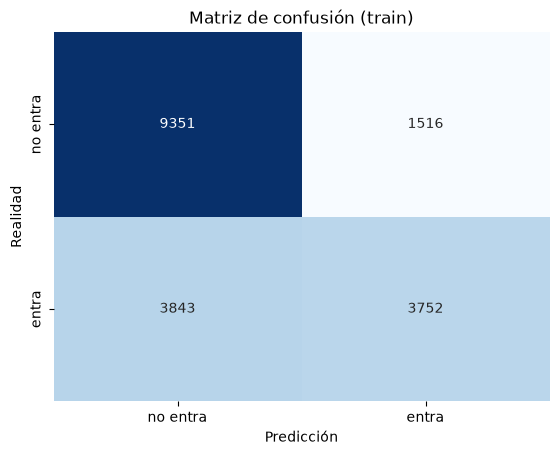

scikit-learn -> accuracy 0.710   precision 0.712   recall 0.494   F1 0.583
AUC: 0.8


In [ ]:
pred_train = knn_ajustado.predict(X_train_esc)     
prob_train = knn_ajustado.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

## Probamos el modelo con test

In [ ]:
X_test_esc = scaler.transform(X_test)
pred_test = knn_ajustado.predict(X_test_esc)     
prob_test = knn_ajustado.predict_proba(X_test_esc)[:, 1]  

predicciones_test = (prob_test >= 0.5).astype(int)

print("MÉTRICAS EN TEST")
print("Accuracy:", accuracy_score(y_test, predicciones_test))
print("Precision:", precision_score(y_test, predicciones_test))
print("Recall:", recall_score(y_test, predicciones_test))
print("F1-score:", f1_score(y_test, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_test, prob_test))

c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


MÉTRICAS EN TEST
Accuracy: 0.6672623883021933
Precision: 0.6415204678362573
Recall: 0.4332543443917852
F1-score: 0.5172088637435172
ROC-AUC: 0.6836103178787097


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


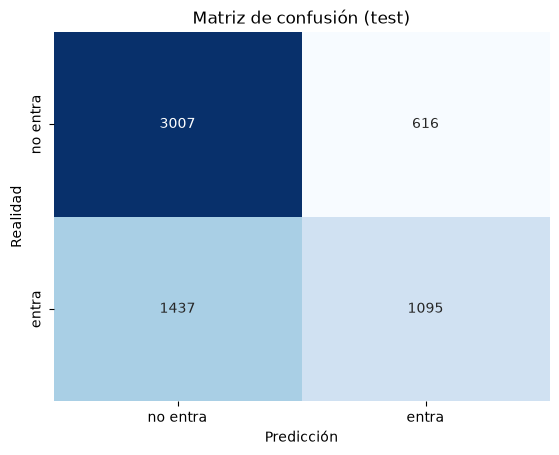

scikit-learn -> accuracy 0.666   precision 0.640   recall 0.432   F1 0.516
AUC: 0.684


In [ ]:
scaler = StandardScaler()
X_test_esc = scaler.fit_transform(X_test)

pred_test = knn_ajustado.predict(X_test_esc)     
prob_test = knn_ajustado.predict_proba(X_test_esc)[:, 1]  

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (test)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_test, pred_test):.3f}   '
      f'precision {precision_score(y_test, pred_test):.3f}   '
      f'recall {recall_score(y_test, pred_test):.3f}   F1 {f1_score(y_test, pred_test):.3f}')

print('AUC:', round(roc_auc_score(y_test, prob_test), 3))

## Guardar modelo:

In [ ]:
joblib.dump(knn_ajustado, "../model/KNN_model.joblib")

print("Modelo guardado correctamente")

Modelo guardado correctamente


## Reflexión final:

Tras evaluar el modelo mediante las métricas F1-score, recall, precisión y ROC-AUC, se observa que sus resultados son moderados y que presenta ciertas limitaciones para el problema planteado.

El F1-score obtenido, de 0.551, refleja un equilibrio limitado entre precisión y recall. Por otra parte, el recall de 0.501 indica que el modelo únicamente identifica aproximadamente la mitad de las canciones que realmente alcanzan el Top 30 de Billboard 100.

Esta limitación resulta especialmente relevante desde el punto de vista empresarial, ya que el objetivo de la IA es ayudar a una discográfica a identificar canciones con potencial comercial antes de tomar decisiones de financiación. No detectar una parte importante de estas canciones podría provocar que se descartasen oportunidades de inversión interesantes.

La precisión de 0.613 muestra que el modelo ofrece cierta capacidad para identificar canciones con potencial, aunque todavía genera un número considerable de predicciones incorrectas. Asimismo, el ROC-AUC de 0.672 refleja una capacidad de discriminación limitada entre ambas clases.

Por estos motivos, aunque el modelo presenta resultados superiores a una clasificación completamente aleatoria, considero que todavía no ofrece un rendimiento suficientemente sólido para utilizarlo como herramienta principal de apoyo a las decisiones de inversión.

No obstante, estos resultados son útiles como punto de partida para comparar diferentes algoritmos y comprender las limitaciones del problema. Por ello, se continuará experimentando con otros modelos, buscando mejorar especialmente el recall, el F1-score y la capacidad de discriminación, sin descuidar la precisión.